# T20 机理笔记（离线 2048 条）

负责人：胡馨澜（Role D）· 任务见 `docs/online-tasks.md` T20
数据：`dataset_same8/train.csv`（2048 行，21 个权重列 + `ramping`）
约束：**本节不调用评估器**，全部结论来自离线表。

三个问题：楼内比例效应、楼间可加性、2 号楼敏感度。每一条都转成 B/C 可用的建模先验。


## 数据与尺度

离线表与评估器**同一尺度**：冒烟测试（`analysis/solver_smoke`）精确复现了 p01969 = 115.76481925917324、
提交 1 = 119.71206678869203、基线 W* = 119.0916。2048 条数据覆盖不到的是响应面的局部形状，不是量纲。

离线 R 范围 115.765–242.521，中位数 161.914。


In [1]:
import json
from pathlib import Path

result = json.loads(Path("results/20261109/results.json").read_text(encoding="utf-8"))

for metric, value in result["share_effect"]["spearman_average_share_vs_R"].items():
    print(f"{metric:12s} {value:+.4f}")
print()
for name, value in result["additivity"].items():
    print(f"{name:38s} {value:.4f}")
print()
for building, value in result["building_sensitivity"]["permutation_r2_drop"].items():
    single = result["building_sensitivity"]["single_building_cv_r2"][building]
    print(f"building {building}: permutation {value:.4f}, single-building R2 {single:.4f}")


cost         +0.1853
carbon       +0.1921
peak         -0.0809
discomfort   -0.0427
degradation  +0.2203
ramping      -0.6434
resilience   -0.0333

gbm_joint_r2                           0.7726
gbm_additive_by_building_r2            0.8090
ridge_additive_linear_r2               0.5143
ridge_plus_within_building_terms_r2    0.6703
ridge_plus_cross_building_terms_r2     0.4466

building 1: permutation 0.9429, single-building R2 0.4585
building 2: permutation 0.0783, single-building R2 -0.1375
building 3: permutation 0.4416, single-building R2 0.1506

## 1. 楼内比例效应

每栋楼的 7 个权重就是份额。三栋平均的 `ramping` 份额与 R 的 Spearman = **−0.6434**，
按份额分 8 档后中位数 R 从 **173.48 单调降到 145.90**。

与更高 R 同向的份额：`degradation`（+0.2203）、`carbon`（+0.1921）、`cost`（+0.1853）；
`peak`、`discomfort`、`resilience` 基本无信号。


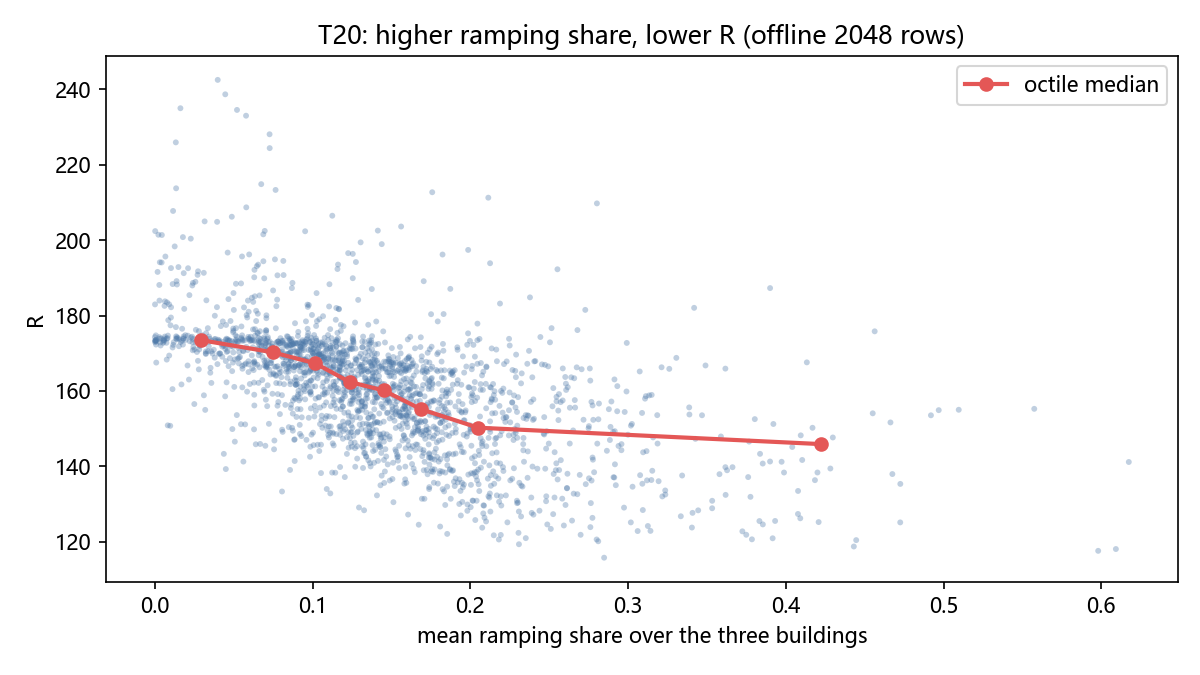

In [ ]:
from IPython.display import Image, display
display(Image(filename="results/20261109/figures/share_vs_R.png"))


## 2. 楼间可加性（已修正）

**修正说明**：初版写的是"三栋独立 GBM 相加 R²=0.2630，可加性不成立"。那是把三个各自拟合的模型
中心化后相加，而不是拟合一个加性模型，结论反向。现在改用 sklearn 的 `interaction_cst`
把交互限制在每栋楼内部，并补充两个线性对照。

| 模型 | 5 折 CV R² |
|---|---|
| ridge，纯加性 | 0.5143 |
| ridge + 楼内平方/乘积项 | 0.6703 |
| ridge + 仅楼间乘积项 | 0.4466 |
| GBM，21 维联合 | 0.7726 |
| GBM，交互限制在楼内 | **0.8090** |

**结论**：真正起作用的是**楼内**交互；跨楼乘积项不但没用，还让线性模型比纯加性更差。
按楼加性建模是合理的归纳偏置，additive ARD GP（v3.2 83.15，0–100 分制，不可与上表 CV R² 直接比较）不应因为"可加"被放弃。


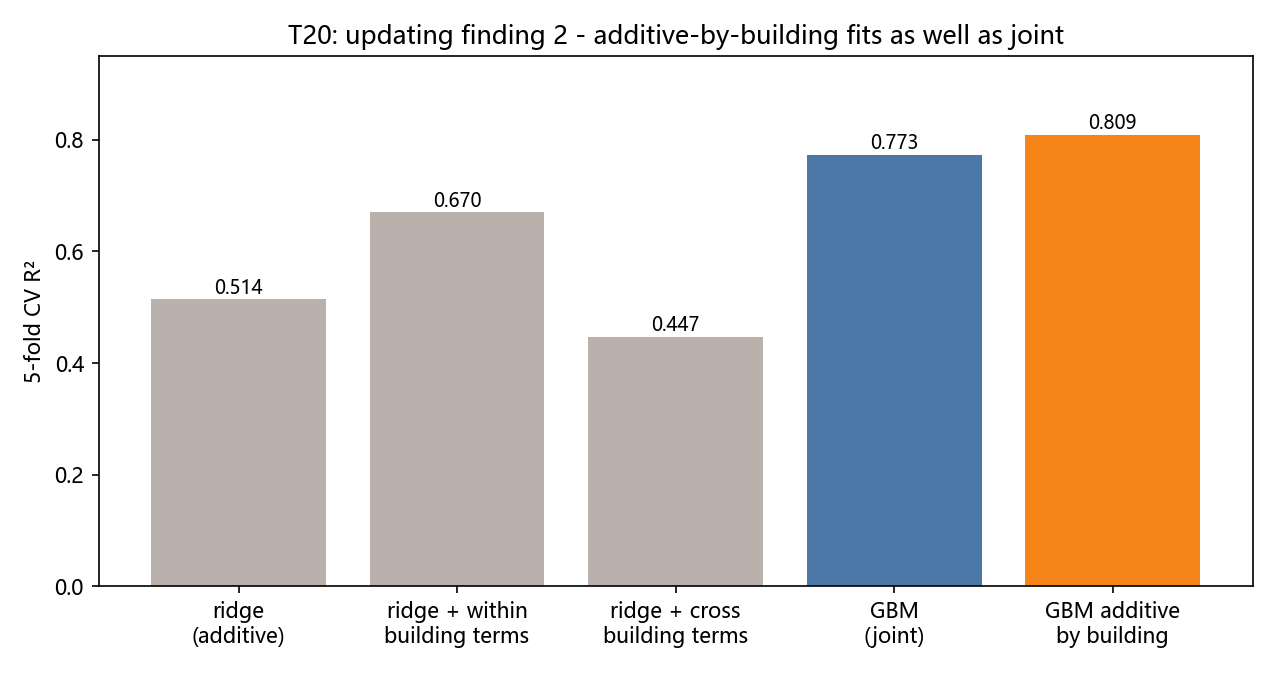

In [ ]:
from IPython.display import Image, display
display(Image(filename="results/20261109/figures/additivity.png"))


## 3. 2 号楼敏感度

分组置换重要性：同一次行置换同时作用于该楼全部 7 个权重，权重和为 1 的组合关系保持不变。

| 楼 | 置换 R² 下降 | 单楼 CV R² |
|---|---|---|
| 1 | 0.9429 | 0.4585 |
| 2 | **0.0783** | **−0.1375** |
| 3 | 0.4416 | 0.1506 |

2 号楼单独建模不如预测均值，打乱它的权重也几乎不动联合模型。它在完整组合里仍有贡献，
但提议预算和特征工程应最后考虑它。

> 修正：初版对 7 列分别独立打乱，破坏了每栋楼权重和为 1 的约束（最大偏差 2.06），
> 曾报告 0.9087 / 0.0728 / 0.4356。改为整块置换后数字如上，排序不变。

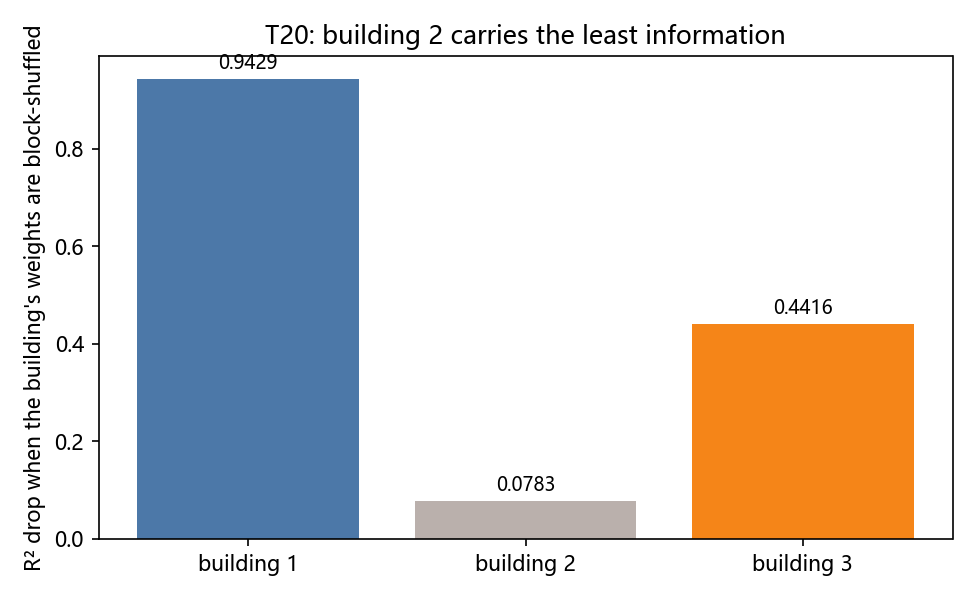

In [ ]:
from IPython.display import Image, display
display(Image(filename="results/20261109/figures/building_sensitivity.png"))


## 交给 B/C 的三条建模先验

1. 用每栋楼的 7 维份额作特征，而不是原始量级；`ramping` 份额是第一杠杆，其次是
   `degradation` / `cost` / `carbon`。
2. 按楼加性建模是合适的；不要为了"可加"放弃 additive ARD GP，也不要加跨楼交互特征。
3. 提议预算优先给 1、3 号楼，2 号楼保持保守。


## 复现

```bash
uv run python analysis/mechanism/study.py
```

种子 0，5 折，`HistGradientBoostingRegressor(max_iter=200)`，`interaction_cst` 按楼分组。
结果写入 `results/<时间戳>/`，本 notebook 引用的是 `results/20261109/`。

## 局限

- 2048 条数据无法分辨评估器响应面上的窄平台和单点凹口。
- 置换重要性依赖模型，不等于因果效应。
- "2 号楼不敏感"是这个样本上的先验，不是在线阶段的保证。
